# Complex EDA: Private Nonprofit Four-Year Colleges

This analysis extends Isabella's initial checks of the IPEDS institution-by-fall panel. It examines panel coverage and data quality, admissions funnel rates, tuition and aid measures, changes over time, and descriptive relationships between price and yield.

**Scope:** fall 2018-2022. The source panel contains private nonprofit four-year institutions that have admissions records. Associations are descriptive, not causal. Interpret estimates alongside their coverage and denominator; missing data and changing institution composition can affect apparent trends.

**Constructed measures:** admit rate = admits / applicants; yield = enrolled / admits; institutional-aid discount proxy = (share of first-time students receiving institutional grants x average institutional grant) / sticker tuition and fees. The discount proxy is an approximate student-level measure, not an institution-wide revenue discount rate.

## 1. Load and validate the panel

Convert IPEDS' `.` missing-value marker in tuition to numeric missingness, then define transparent rate measures. Assertions check that the panel key and expected time range are present.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

DATA_PATH = Path("../DATA/PROCESSED/postsecondary_panel.csv.gz")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected processed panel at {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
if "sticker_tuition_fees" not in df.columns:
    raise KeyError("The processed panel is missing sticker_tuition_fees")

df["sticker_tuition_fees"] = pd.to_numeric(
    df["sticker_tuition_fees"].replace(".", np.nan), errors="coerce"
)

assert {2018, 2019, 2020, 2021, 2022} == set(df["fall_year"].dropna().astype(int))
assert not df.duplicated(["unitid", "fall_year"]).any(), "Duplicate institution-year keys found"

df["admit_rate"] = df["admits"].div(df["applicants"].where(df["applicants"] > 0))
df["yield_rate"] = df["enrolled"].div(df["admits"].where(df["admits"] > 0))
df["estimated_institutional_aid_per_first_time_student"] = (
    df["first_time_percent_institutional_grant"].div(100)
    * df["first_time_average_institutional_grant"]
)
df["institutional_discount_proxy"] = (
    df["estimated_institutional_aid_per_first_time_student"]
    / df["sticker_tuition_fees"].where(df["sticker_tuition_fees"] > 0)
)
df["net_price_share_of_sticker"] = (
    df["average_net_price"] / df["sticker_tuition_fees"].where(df["sticker_tuition_fees"] > 0)
)

print(f"Panel shape: {df.shape[0]:,} rows x {df.shape[1]} columns (including derived rates)")
print(f"Institutions: {df['unitid'].nunique():,}; years: {df['fall_year'].min()}-{df['fall_year'].max()}")
print(f"Duplicate institution-year keys: {df.duplicated(['unitid', 'fall_year']).sum()}")
print("\nCoverage by year:")
coverage = df.groupby("fall_year").agg(
    institution_years=("unitid", "size"),
    institutions=("unitid", "nunique"),
    median_applicants=("applicants", "median"),
    median_admits=("admits", "median"),
    median_enrolled=("enrolled", "median"),
)
print(coverage.round(1).to_string())
counts_per_institution = df.groupby("unitid")["fall_year"].nunique()
print(f"\nInstitutions present in all 5 years: {(counts_per_institution == 5).sum():,}")
print(f"Institutions present in 1-4 years: {(counts_per_institution < 5).sum():,}")
print("\nData types:")
print(df.dtypes.astype(str).to_string())

Panel shape: 5,662 rows x 27 columns (including derived rates)
Institutions: 1,211; years: 2018-2022
Duplicate institution-year keys: 0

Coverage by year:
           institution_years  institutions  median_applicants  median_admits  median_enrolled
fall_year                                                                                    
2018                    1142          1142             2001.5         1279.0            304.5
2019                    1138          1138             2003.0         1277.0            295.0
2020                    1135          1135             1898.0         1302.5            282.0
2021                    1125          1125             1858.0         1275.0            272.5
2022                    1122          1122             1993.5         1354.0            276.0

Institutions present in all 5 years: 1,059
Institutions present in 1-4 years: 152

Data types:
unitid                                                  int64
fall_year                    

## 2. Data quality, missingness, and admissions checks

Missingness is reported by column and year rather than summarized as a single panel-wide percentage. Range checks flag potentially meaningful values without silently dropping or winsorizing them.

In [2]:
key_vars = [
    "applicants", "admits", "enrolled", "sticker_tuition_fees", "average_net_price",
    "first_time_percent_institutional_grant", "first_time_average_institutional_grant",
    "institutional_discount_proxy", "tuition_fee_revenue", "allowances_endowment_gifts_tuition",
    "allowances_other_institutional_tuition",
]
missing = pd.DataFrame({
    "missing_n": df[key_vars].isna().sum(),
    "missing_pct": 100 * df[key_vars].isna().mean(),
}).sort_values("missing_pct", ascending=False)
print("Missingness across all institution-years:")
print(missing.round(1).to_string())

missing_by_year = df.groupby("fall_year")[key_vars].apply(lambda x: 100 * x.isna().mean())
print("\nMissingness by year (% of institution-years):")
print(missing_by_year.round(1).to_string())

checks = {
    "applicants <= 0": df["applicants"].le(0),
    "admits < 0": df["admits"].lt(0),
    "admits > applicants": df["admits"].gt(df["applicants"]),
    "enrolled < 0": df["enrolled"].lt(0),
    "enrolled > admits": df["enrolled"].gt(df["admits"]),
    "nonmissing grant percentage outside 0-100": (
        df["first_time_percent_institutional_grant"].notna()
        & ~df["first_time_percent_institutional_grant"].between(0, 100)
    ),
    "nonpositive sticker tuition": df["sticker_tuition_fees"].le(0),
    "negative net price": df["average_net_price"].lt(0),
    "discount proxy > 100%": df["institutional_discount_proxy"].gt(1),
}
print("\nRange/consistency flags (nulls are not counted as violations):")
for label, mask in checks.items():
    print(f"{label}: {int(mask.fillna(False).sum()):,}")

print("\nFinance allowance coverage by year (missing/rows):")
allowance_missing = df.groupby("fall_year")[[
    "allowances_endowment_gifts_tuition", "allowances_other_institutional_tuition"
]].agg(lambda x: f"{x.isna().sum()}/{len(x)} ({100*x.isna().mean():.1f}%)")
print(allowance_missing.to_string())

Missingness across all institution-years:
                                        missing_n  missing_pct
allowances_endowment_gifts_tuition           1251         22.1
allowances_other_institutional_tuition       1251         22.1
institutional_discount_proxy                  328          5.8
first_time_average_institutional_grant        318          5.6
average_net_price                             192          3.4
first_time_percent_institutional_grant        150          2.6
tuition_fee_revenue                           138          2.4
enrolled                                       46          0.8
admits                                         38          0.7
sticker_tuition_fees                           27          0.5
applicants                                      0          0.0

Missingness by year (% of institution-years):
           applicants  admits  enrolled  sticker_tuition_fees  average_net_price  first_time_percent_institutional_grant  first_time_average_institutional_

## 3. Admissions funnel and yield

Unit-level rates require positive denominators. Pooled yield is also shown as total enrolled divided by total admits, so large institutions contribute in proportion to admitted cohort size. A sensitivity table shows results with minimum admitted-cohort thresholds.

In [3]:
valid_yield = df["yield_rate"].notna() & np.isfinite(df["yield_rate"])
valid_admit = df["admit_rate"].notna() & np.isfinite(df["admit_rate"])
print(f"Rows with computable yield: {valid_yield.sum():,}/{len(df):,}")
print(f"Rows with computable admit rate: {valid_admit.sum():,}/{len(df):,}")
print(f"Rows with fewer than 50 admits: {df['admits'].lt(50).sum():,}")
print(f"Rows with exactly 100% yield: {df['yield_rate'].eq(1).sum():,}")
print(f"Yield outside 0-100%: {((df['yield_rate'] < 0) | (df['yield_rate'] > 1)).sum():,}")

annual_rows = []
for year, g in df.groupby("fall_year", sort=True):
    y = g.loc[g["yield_rate"].notna(), "yield_rate"]
    a = g.loc[g["admit_rate"].notna(), "admit_rate"]
    pooled = g.loc[g["admits"].gt(0) & g["enrolled"].notna()]
    annual_rows.append({
        "year": year, "yield_n": len(y), "median_yield_pct": 100 * y.median(),
        "q1_yield_pct": 100 * y.quantile(.25), "q3_yield_pct": 100 * y.quantile(.75),
        "pooled_yield_pct": 100 * pooled["enrolled"].sum() / pooled["admits"].sum(),
        "median_admit_rate_pct": 100 * a.median(), "median_applicants": g["applicants"].median(),
    })
annual_rates = pd.DataFrame(annual_rows).set_index("year")
print("\nAnnual yield and admit-rate summaries:")
print(annual_rates.round(1).to_string())

sensitivity = []
for minimum_admits in [1, 50, 100]:
    subset = df.loc[df["admits"].ge(minimum_admits) & df["yield_rate"].notna()]
    for year, g in subset.groupby("fall_year", sort=True):
        sensitivity.append({
            "minimum_admits": minimum_admits, "year": year, "rows": len(g),
            "median_yield_pct": 100 * g["yield_rate"].median(),
            "pooled_yield_pct": 100 * g["enrolled"].sum() / g["admits"].sum(),
        })
sensitivity = pd.DataFrame(sensitivity)
print("\nSensitivity: median yield (%) by minimum admits threshold:")
print(sensitivity.pivot(index="year", columns="minimum_admits", values="median_yield_pct").round(1).to_string())
print("\nValid institution-year counts at each threshold:")
print(sensitivity.pivot(index="year", columns="minimum_admits", values="rows").to_string())

Rows with computable yield: 5,616/5,662
Rows with computable admit rate: 5,624/5,662
Rows with fewer than 50 admits: 693
Rows with exactly 100% yield: 220
Yield outside 0-100%: 0

Annual yield and admit-rate summaries:
      yield_n  median_yield_pct  q1_yield_pct  q3_yield_pct  pooled_yield_pct  median_admit_rate_pct  median_applicants
year                                                                                                                   
2018     1126              26.3          17.9          43.4              21.7                   67.7             2001.5
2019     1132              24.9          17.1          44.6              21.0                   69.2             2003.0
2020     1125              23.0          15.9          42.2              19.0                   71.8             1898.0
2021     1118              22.3          15.6          44.2              19.4                   75.4             1858.0
2022     1115              21.9          15.0          45.1  

## 4. Panel composition and within-institution change

Compare the unbalanced panel with a balanced five-year subset to see whether changing institutional composition alters the yield pattern. Paired 2018-to-2022 changes describe the same institutions; they are not estimates of a pandemic effect.

In [4]:
wide_yield = df.pivot(index="unitid", columns="fall_year", values="yield_rate")
balanced_ids = wide_yield.dropna(subset=[2018, 2019, 2020, 2021, 2022]).index
balanced = df.loc[df["unitid"].isin(balanced_ids)]
balanced_medians = 100 * balanced.groupby("fall_year")["yield_rate"].median()
paired = wide_yield.dropna(subset=[2018, 2022]).assign(change_18_22=lambda x: x[2022] - x[2018])
print(f"Balanced institutions with valid yield in every year: {len(balanced_ids):,}")
print(f"Institutions with valid yield in both 2018 and 2022: {len(paired):,}")
print("\nAnnual median yield, all available institutions vs balanced panel (%):")
trend_compare = pd.DataFrame({
    "all_available": 100 * df.groupby("fall_year")["yield_rate"].median(),
    "balanced_panel": balanced_medians,
})
print(trend_compare.round(1).to_string())
print(f"\nMedian institution-level 2018-2022 yield change: {100*paired['change_18_22'].median():.2f} percentage points")
print(f"25th-75th percentile of paired change: {100*paired['change_18_22'].quantile(.25):.2f} to {100*paired['change_18_22'].quantile(.75):.2f} pp")
print(f"Institutions with higher yield in 2022 than 2018: {(paired['change_18_22'] > 0).sum():,} ({100*(paired['change_18_22'] > 0).mean():.1f}%)")

print("\n2022 median rates by IPEDS size-category code:")
size_2022 = df.loc[df["fall_year"].eq(2022)].groupby("size_category").agg(
    institutions=("unitid", "nunique"), valid_yield=("yield_rate", "count"),
    median_yield=("yield_rate", "median"), median_admit_rate=("admit_rate", "median"),
)
size_2022["median_yield_pct"] = 100 * size_2022.pop("median_yield")
size_2022["median_admit_rate_pct"] = 100 * size_2022.pop("median_admit_rate")
print(size_2022.round(1).to_string())
print("\n2022 median yield by locale code (codes retained as reported):")
locale_2022 = df.loc[df["fall_year"].eq(2022)].groupby("locale").agg(
    institutions=("unitid", "nunique"), median_yield=("yield_rate", "median"),
)
locale_2022["median_yield_pct"] = 100 * locale_2022.pop("median_yield")
print(locale_2022.round(1).to_string())


Balanced institutions with valid yield in every year: 1,049
Institutions with valid yield in both 2018 and 2022: 1,054

Annual median yield, all available institutions vs balanced panel (%):
           all_available  balanced_panel
fall_year                               
2018                26.3            26.2
2019                24.9            24.4
2020                23.0            22.5
2021                22.3            21.8
2022                21.9            21.1

Median institution-level 2018-2022 yield change: -2.93 percentage points
25th-75th percentile of paired change: -7.19 to 0.92 pp
Institutions with higher yield in 2022 than 2018: 312 (29.6%)

2022 median rates by IPEDS size-category code:
               institutions  valid_yield  median_yield_pct  median_admit_rate_pct
size_category                                                                    
-1                        1            1              66.7                   54.5
 1                      388         

## 5. Tuition, net price, and institutional aid

Sticker tuition and average net price are distinct measures. The aid discount proxy uses the first-time cohort's institutional-grant receipt share and average grant. We report coverage and out-of-range values before examining descriptive, within-year associations with yield.

In [5]:
price_vars = [
    "sticker_tuition_fees", "average_net_price", "first_time_percent_institutional_grant",
    "first_time_average_institutional_grant", "institutional_discount_proxy", "net_price_share_of_sticker",
]
price_coverage = df.groupby("fall_year")[price_vars].agg(lambda x: f"{x.notna().sum()}/{len(x)} ({100*x.notna().mean():.1f}%)")
print("Price/aid coverage by year (observed/rows):")
print(price_coverage.to_string())

price_summary = df.groupby("fall_year").agg(
    median_sticker=("sticker_tuition_fees", "median"),
    median_net_price=("average_net_price", "median"),
    median_discount_proxy=("institutional_discount_proxy", "median"),
    p90_discount_proxy=("institutional_discount_proxy", lambda x: x.quantile(.9)),
    median_net_to_sticker=("net_price_share_of_sticker", "median"),
)
print("\nAnnual medians (dollars except ratios):")
print(price_summary.round(3).to_string())

valid_discount = df["institutional_discount_proxy"].notna()
print(f"\nRows with computable institutional discount proxy: {valid_discount.sum():,}")
print(f"Proxy over 100% of sticker tuition: {(df['institutional_discount_proxy'] > 1).sum():,}")
print(f"Proxy negative: {(df['institutional_discount_proxy'] < 0).sum():,}")

corr_rows = []
for year, g in df.groupby("fall_year", sort=True):
    for var, label in [
        ("sticker_tuition_fees", "Sticker tuition"),
        ("average_net_price", "Average net price"),
        ("institutional_discount_proxy", "Institutional discount proxy"),
    ]:
        paired = g[["yield_rate", var]].dropna()
        paired = paired.loc[np.isfinite(paired["yield_rate"]) & np.isfinite(paired[var])]
        if len(paired) >= 3:
            x = paired["yield_rate"].rank(method="average").to_numpy(dtype=float)
            y = paired[var].rank(method="average").to_numpy(dtype=float)
            x = x - x.mean()
            y = y - y.mean()
            denominator = np.sqrt((x * x).sum() * (y * y).sum())
            rho = float((x * y).sum() / denominator) if denominator else np.nan
        else:
            rho = np.nan
        corr_rows.append({"year": year, "measure": label, "n": len(paired), "spearman_rho": rho})
correlations = pd.DataFrame(corr_rows)
print("\nWithin-year Spearman association with institution yield:")
print(correlations.pivot(index="measure", columns="year", values="spearman_rho").round(2).to_string())
print("\nPair counts used for each association:")
print(correlations.pivot(index="measure", columns="year", values="n").to_string())

scatter_eligible = df["yield_rate"].between(0, 1) & df["institutional_discount_proxy"].between(0, 1)
print(f"In-range rows for a yield/discount comparison: {scatter_eligible.sum():,}; excluded for missing or out-of-range measures: {(~scatter_eligible).sum():,}.")

Price/aid coverage by year (observed/rows):
          sticker_tuition_fees  average_net_price first_time_percent_institutional_grant first_time_average_institutional_grant institutional_discount_proxy net_price_share_of_sticker
fall_year                                                                                                                                                                              
2018         1133/1142 (99.2%)  1097/1142 (96.1%)                      1102/1142 (96.5%)                      1084/1142 (94.9%)            1081/1142 (94.7%)          1094/1142 (95.8%)
2019         1132/1138 (99.5%)  1105/1138 (97.1%)                      1107/1138 (97.3%)                      1081/1138 (95.0%)            1078/1138 (94.7%)          1102/1138 (96.8%)
2020         1130/1135 (99.6%)  1100/1135 (96.9%)                      1110/1135 (97.8%)                      1062/1135 (93.6%)            1060/1135 (93.4%)          1097/1135 (96.7%)
2021         1122/1125 (99.7%)  1089

## 6. Visual exploration

These inline SVG charts complement the tables with yearly trends, yield distributions, field coverage, pricing relationships, and state variation. Quantile lines and median overlays are descriptive guides; they do not imply causal effects. SVGs are generated directly so the notebook does not depend on the unstable Matplotlib rendering backend.


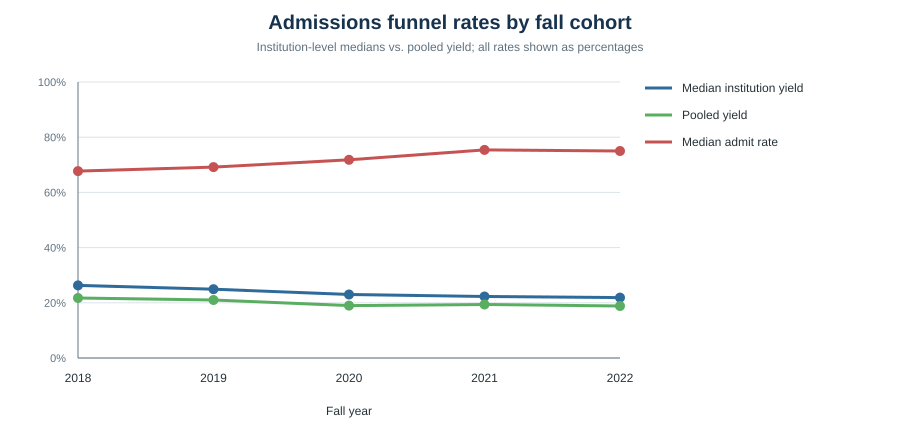

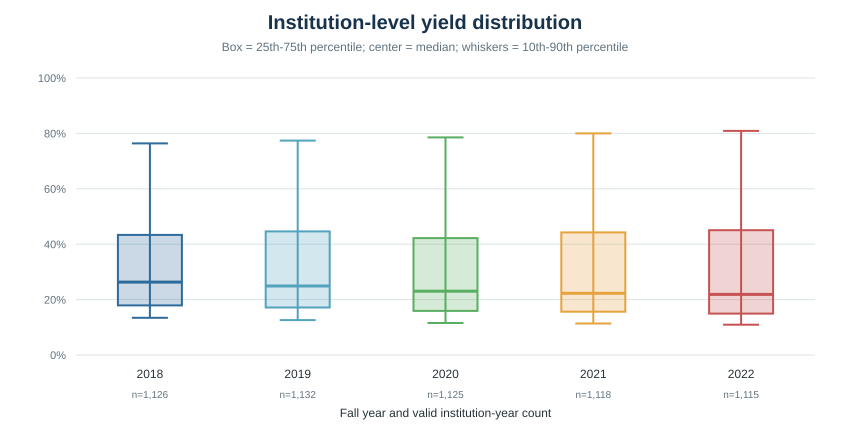

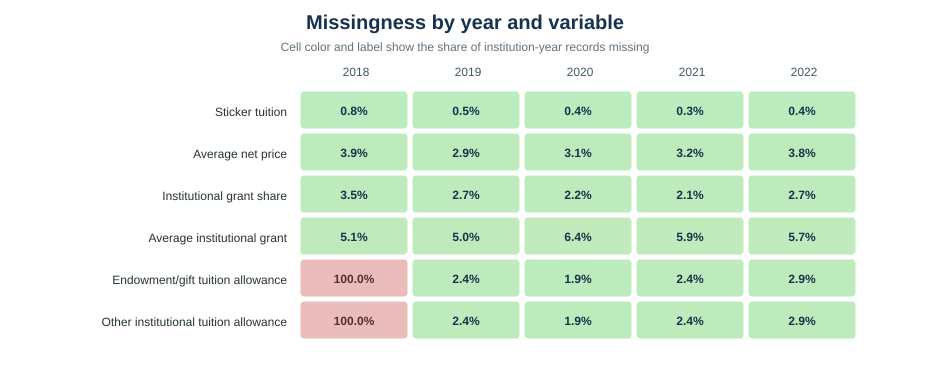

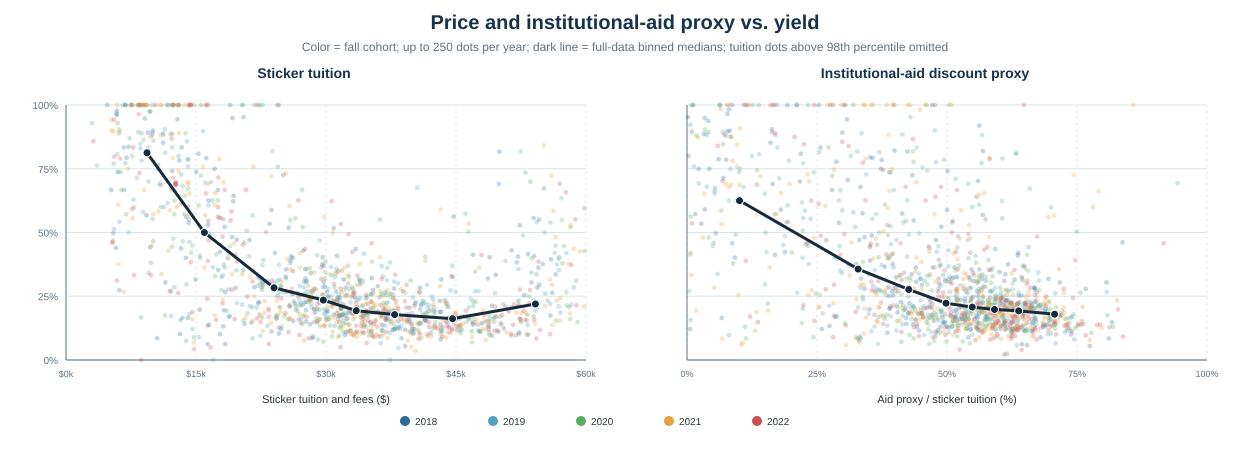

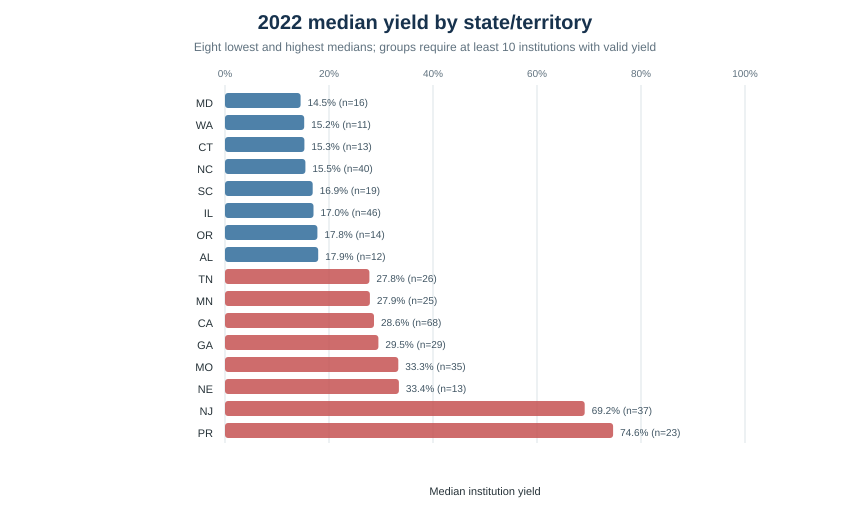

Scatter coverage: 5,593 tuition/yield pairs; 5,314 in-range aid-proxy/yield pairs.
Dots are deterministically sampled by year (up to 250 per year per panel); binned median lines use all eligible records.


In [6]:
from IPython.display import SVG
from xml.etree import ElementTree

CHART_COLORS = {2018: "#2F6B9A", 2019: "#53A2BE", 2020: "#5AAE61", 2021: "#E6A23C", 2022: "#C65353"}
TEXT_COLOR = "#263238"
GRID_COLOR = "#DCE3E8"


def chart_text(x, y, label, size=13, anchor="middle", color=TEXT_COLOR, extra=""):
    safe_label = str(label).replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    return f'<text x="{x:.1f}" y="{y:.1f}" text-anchor="{anchor}" font-family="Arial, sans-serif" font-size="{size}" fill="{color}" {extra}>{safe_label}</text>'


def chart_open(width, height, title, subtitle):
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}" viewBox="0 0 {width} {height}">']
    parts.append(f'<rect width="100%" height="100%" fill="#FFFFFF"/>')
    parts.append(chart_text(width / 2, 29, title, 20, color="#17324D", extra="font-weight=\"700\""))
    parts.append(chart_text(width / 2, 51, subtitle, 12, color="#60727F"))
    return parts


def chart_finish(parts):
    parts.append("</svg>")
    svg = "".join(parts)
    ElementTree.fromstring(svg)
    return SVG(svg)


# 1. Cohort-level admissions funnel trends.
trend = df.groupby("fall_year").agg(
    median_yield=("yield_rate", "median"),
    median_admit_rate=("admit_rate", "median"),
)
pooled = df.loc[df["admits"].gt(0) & df["enrolled"].notna()].groupby("fall_year").apply(
    lambda g: g["enrolled"].sum() / g["admits"].sum(), include_groups=False
)
trend["pooled_yield"] = pooled
width, height = 900, 430
left, right, top, bottom = 78, 280, 82, 72
plot_width, plot_height = width - left - right, height - top - bottom
parts = chart_open(width, height, "Admissions funnel rates by fall cohort", "Institution-level medians vs. pooled yield; all rates shown as percentages")
for tick in range(0, 101, 20):
    y = top + plot_height * (1 - tick / 100)
    parts.append(f'<line x1="{left}" y1="{y:.1f}" x2="{left + plot_width}" y2="{y:.1f}" stroke="{GRID_COLOR}"/>')
    parts.append(chart_text(left - 12, y + 4, f"{tick}%", 11, anchor="end", color="#60727F"))
parts.append(f'<line x1="{left}" y1="{top}" x2="{left}" y2="{top + plot_height}" stroke="#627581"/>')
parts.append(f'<line x1="{left}" y1="{top + plot_height}" x2="{left + plot_width}" y2="{top + plot_height}" stroke="#627581"/>')
years = list(trend.index)
points_for = {}
series = [
    ("median_yield", "Median institution yield", "#2F6B9A"),
    ("pooled_yield", "Pooled yield", "#5AAE61"),
    ("median_admit_rate", "Median admit rate", "#C65353"),
]
for key, label, color in series:
    points = []
    for i, year in enumerate(years):
        value = float(trend.loc[year, key]) * 100
        x = left + plot_width * i / max(1, len(years) - 1)
        y = top + plot_height * (1 - value / 100)
        points.append((x, y))
        parts.append(f'<circle cx="{x:.1f}" cy="{y:.1f}" r="5" fill="{color}"/>')
    parts.append(f'<polyline points="{" ".join(f"{x:.1f},{y:.1f}" for x, y in points)}" fill="none" stroke="{color}" stroke-width="3"/>')
    points_for[label] = color
for i, year in enumerate(years):
    x = left + plot_width * i / max(1, len(years) - 1)
    parts.append(chart_text(x, top + plot_height + 24, year, 12))
for i, (label, color) in enumerate(points_for.items()):
    y = top + 10 + i * 27
    parts.append(f'<line x1="{left + plot_width + 25}" y1="{y - 4}" x2="{left + plot_width + 52}" y2="{y - 4}" stroke="{color}" stroke-width="3"/>')
    parts.append(chart_text(left + plot_width + 62, y, label, 12, anchor="start"))
parts.append(chart_text(left + plot_width / 2, height - 15, "Fall year", 12))
display(chart_finish(parts))


# 2. Distribution of institution yield; whiskers show the 10th-90th percentile.
width, height = 850, 430
left, right, top, bottom = 76, 35, 78, 75
plot_width, plot_height = width - left - right, height - top - bottom
parts = chart_open(width, height, "Institution-level yield distribution", "Box = 25th-75th percentile; center = median; whiskers = 10th-90th percentile")
for tick in range(0, 101, 20):
    y = top + plot_height * (1 - tick / 100)
    parts.append(f'<line x1="{left}" y1="{y:.1f}" x2="{left + plot_width}" y2="{y:.1f}" stroke="{GRID_COLOR}"/>')
    parts.append(chart_text(left - 10, y + 4, f"{tick}%", 11, anchor="end", color="#60727F"))
for i, year in enumerate(years):
    values = (100 * df.loc[df["fall_year"].eq(year), "yield_rate"].dropna()).to_numpy()
    p10, q1, median, q3, p90 = np.quantile(values, [0.10, 0.25, 0.50, 0.75, 0.90])
    x = left + plot_width * (i + 0.5) / len(years)
    y_for = lambda value: top + plot_height * (1 - value / 100)
    box_width = 64
    color = CHART_COLORS[int(year)]
    parts.append(f'<line x1="{x:.1f}" y1="{y_for(p10):.1f}" x2="{x:.1f}" y2="{y_for(p90):.1f}" stroke="{color}" stroke-width="2"/>')
    parts.append(f'<line x1="{x - 18:.1f}" y1="{y_for(p10):.1f}" x2="{x + 18:.1f}" y2="{y_for(p10):.1f}" stroke="{color}" stroke-width="2"/>')
    parts.append(f'<line x1="{x - 18:.1f}" y1="{y_for(p90):.1f}" x2="{x + 18:.1f}" y2="{y_for(p90):.1f}" stroke="{color}" stroke-width="2"/>')
    parts.append(f'<rect x="{x - box_width/2:.1f}" y="{y_for(q3):.1f}" width="{box_width}" height="{y_for(q1)-y_for(q3):.1f}" fill="{color}" fill-opacity="0.25" stroke="{color}" stroke-width="2"/>')
    parts.append(f'<line x1="{x - box_width/2:.1f}" y1="{y_for(median):.1f}" x2="{x + box_width/2:.1f}" y2="{y_for(median):.1f}" stroke="{color}" stroke-width="3"/>')
    parts.append(chart_text(x, top + plot_height + 23, year, 12))
    parts.append(chart_text(x, top + plot_height + 43, f"n={len(values):,}", 10, color="#60727F"))
parts.append(chart_text(left + plot_width / 2, height - 13, "Fall year and valid institution-year count", 12))
display(chart_finish(parts))


# 3. Missingness heatmap highlights the structural 2018 finance-data gap.
heat_vars = [
    ("Sticker tuition", "sticker_tuition_fees"),
    ("Average net price", "average_net_price"),
    ("Institutional grant share", "first_time_percent_institutional_grant"),
    ("Average institutional grant", "first_time_average_institutional_grant"),
    ("Endowment/gift tuition allowance", "allowances_endowment_gifts_tuition"),
    ("Other institutional tuition allowance", "allowances_other_institutional_tuition"),
]
missing_pct = df.groupby("fall_year")[[column for _, column in heat_vars]].apply(lambda g: 100 * g.isna().mean())
width, height = 930, 390
left, top, cell_width, cell_height = 300, 91, 112, 42
parts = chart_open(width, height, "Missingness by year and variable", "Cell color and label show the share of institution-year records missing")
for j, year in enumerate(years):
    parts.append(chart_text(left + j * cell_width + cell_width/2, top - 15, year, 12, color="#405563"))
for i, (label, column) in enumerate(heat_vars):
    y = top + i * cell_height
    parts.append(chart_text(left - 13, y + 25, label, 12, anchor="end"))
    for j, year in enumerate(years):
        value = float(missing_pct.loc[year, column])
        hue = 122 * (1 - min(value, 100) / 100)
        fill = f"hsl({hue:.0f}, 55%, 83%)"
        x = left + j * cell_width
        parts.append(f'<rect x="{x}" y="{y}" width="{cell_width-4}" height="{cell_height-4}" rx="4" fill="{fill}" stroke="#FFFFFF"/>')
        text_color = "#17324D" if value < 60 else "#5A2D2D"
        parts.append(chart_text(x + (cell_width-4)/2, y + 24, f"{value:.1f}%", 12, color=text_color, extra="font-weight=\"600\""))
display(chart_finish(parts))


# 4. Scatter plots for yield vs. sticker tuition and the aid proxy, with binned medians.
def scatter_panel(parts, values, x_label, x_max, x_format, x0, panel_width, top, plot_height, title):
    x_values, y_values, years_values = values
    panel_left = x0 + 62
    panel_right = x0 + panel_width - 18
    width_inner = panel_right - panel_left
    parts.append(chart_text(x0 + panel_width/2, 78, title, 14, color="#17324D", extra="font-weight=\"700\""))
    for tick in range(0, 101, 25):
        y = top + plot_height * (1 - tick/100)
        parts.append(f'<line x1="{panel_left}" y1="{y:.1f}" x2="{panel_right}" y2="{y:.1f}" stroke="{GRID_COLOR}"/>')
        if x0 < 500:
            parts.append(chart_text(panel_left - 8, y + 4, f"{tick}%", 10, anchor="end", color="#60727F"))
    for tick in range(0, 5):
        value = x_max * tick / 4
        x = panel_left + width_inner * tick / 4
        parts.append(f'<line x1="{x:.1f}" y1="{top}" x2="{x:.1f}" y2="{top+plot_height}" stroke="{GRID_COLOR}" stroke-dasharray="2,4"/>')
        parts.append(chart_text(x, top + plot_height + 17, x_format(value), 9, color="#60727F"))
    parts.append(f'<line x1="{panel_left}" y1="{top}" x2="{panel_left}" y2="{top+plot_height}" stroke="#627581"/>')
    parts.append(f'<line x1="{panel_left}" y1="{top+plot_height}" x2="{panel_right}" y2="{top+plot_height}" stroke="#627581"/>')
    rng = np.random.default_rng(511)
    display_indices = []
    for year in years:
        year_indices = np.flatnonzero(years_values == year)
        display_indices.extend(rng.choice(year_indices, min(250, len(year_indices)), replace=False))
    for index in display_indices:
        x_value, y_value, year = x_values[index], y_values[index], years_values[index]
        if x_value <= x_max:
            x = panel_left + width_inner * x_value / x_max
            y = top + plot_height * (1 - 100*y_value/100)
            parts.append(f'<circle cx="{x:.1f}" cy="{y:.1f}" r="2.4" fill="{CHART_COLORS[int(year)]}" fill-opacity="0.28"/>')
    selected = [(float(x), float(y)) for x, y in zip(x_values, y_values) if np.isfinite(x) and np.isfinite(y) and 0 <= x <= x_max and 0 <= y <= 1]
    edges = np.quantile([pair[0] for pair in selected], np.linspace(0, 1, 9))
    medians = []
    for i in range(len(edges) - 1):
        bucket = [pair for pair in selected if edges[i] <= pair[0] <= edges[i+1] and (i == len(edges)-2 or pair[0] < edges[i+1])]
        if bucket:
            medians.append((float(np.median([pair[0] for pair in bucket])), float(np.median([pair[1] for pair in bucket]))))
    if len(medians) > 1:
        coords = " ".join(f"{panel_left + width_inner*x/x_max:.1f},{top + plot_height*(1-y):.1f}" for x, y in medians)
        parts.append(f'<polyline points="{coords}" fill="none" stroke="#172A3A" stroke-width="3"/>')
        for x_value, y_value in medians:
            x = panel_left + width_inner*x_value/x_max
            y = top + plot_height*(1-y_value)
            parts.append(f'<circle cx="{x:.1f}" cy="{y:.1f}" r="4" fill="#172A3A" stroke="white" stroke-width="1"/>')
    parts.append(chart_text(panel_left + width_inner/2, top + plot_height + 43, x_label, 11))

valid_tuition = df["yield_rate"].between(0, 1) & df["sticker_tuition_fees"].gt(0)
tuition_rows = df.loc[valid_tuition, ["sticker_tuition_fees", "yield_rate", "fall_year"]]
valid_discount = df["yield_rate"].between(0, 1) & df["institutional_discount_proxy"].between(0, 1)
discount_rows = df.loc[valid_discount, ["institutional_discount_proxy", "yield_rate", "fall_year"]]
tu_max = float(tuition_rows["sticker_tuition_fees"].quantile(.98))
discount_max = 1.0
width, height = 1250, 465
plot_top, plot_height = 105, 255
parts = chart_open(width, height, "Price and institutional-aid proxy vs. yield", "Color = fall cohort; up to 250 dots per year; dark line = full-data binned medians; tuition dots above 98th percentile omitted")
scatter_panel(parts, (tuition_rows["sticker_tuition_fees"].to_numpy(), tuition_rows["yield_rate"].to_numpy(), tuition_rows["fall_year"].to_numpy()), "Sticker tuition and fees ($)", tu_max, lambda x: f"${x/1000:.0f}k", 4, 600, plot_top, plot_height, "Sticker tuition")
scatter_panel(parts, (discount_rows["institutional_discount_proxy"].to_numpy(), discount_rows["yield_rate"].to_numpy(), discount_rows["fall_year"].to_numpy()), "Aid proxy / sticker tuition (%)", discount_max, lambda x: f"{x*100:.0f}%", 625, 600, plot_top, plot_height, "Institutional-aid discount proxy")
legend_x = 405
for i, year in enumerate(years):
    x = legend_x + i * 88
    parts.append(f'<circle cx="{x}" cy="421" r="5" fill="{CHART_COLORS[int(year)]}"/>')
    parts.append(chart_text(x + 10, 425, year, 10, anchor="start"))
display(chart_finish(parts))
print(f"Scatter coverage: {len(tuition_rows):,} tuition/yield pairs; {len(discount_rows):,} in-range aid-proxy/yield pairs.")
print("Dots are deterministically sampled by year (up to 250 per year per panel); binned median lines use all eligible records.")


# 5. Show high and low 2022 state/territory medians with group counts.
state = df.loc[df["fall_year"].eq(2022) & df["yield_rate"].between(0, 1)].groupby("state").agg(
    institutions=("unitid", "nunique"), median_yield=("yield_rate", "median")
)
state = state.loc[state["institutions"].ge(10)].copy()
state["median_pct"] = 100 * state.pop("median_yield")
shown = pd.concat([state.nsmallest(8, "median_pct"), state.nlargest(8, "median_pct")]).drop_duplicates().sort_values("median_pct")
width, height = 850, 505
left, top, plot_width, row_height = 225, 93, 520, 22
parts = chart_open(width, height, "2022 median yield by state/territory", "Eight lowest and highest medians; groups require at least 10 institutions with valid yield")
for tick in range(0, 101, 20):
    x = left + plot_width * tick / 100
    parts.append(f'<line x1="{x:.1f}" y1="{top-8}" x2="{x:.1f}" y2="{top + row_height*len(shown)-2}" stroke="{GRID_COLOR}"/>')
    parts.append(chart_text(x, top - 16, f"{tick}%", 10, color="#60727F"))
for i, (state_code, row) in enumerate(shown.iterrows()):
    y = top + i * row_height
    color = "#2F6B9A" if i < 8 else "#C65353"
    bar_width = plot_width * float(row["median_pct"]) / 100
    parts.append(chart_text(left - 12, y + 14, state_code, 11, anchor="end"))
    parts.append(f'<rect x="{left}" y="{y}" width="{bar_width:.1f}" height="15" rx="3" fill="{color}" fill-opacity="0.85"/>')
    parts.append(chart_text(left + bar_width + 7, y + 13, f"{row['median_pct']:.1f}% (n={int(row['institutions'])})", 10, anchor="start", color="#405563"))
parts.append(chart_text(left + plot_width/2, height - 10, "Median institution yield", 11))
display(chart_finish(parts))


## 7. Geographic variation (2022 snapshot)

State comparisons include institutions with computable yield and at least 10 valid institutions per state. These unadjusted summaries are descriptive; they are not adjusted for selectivity, size, or student composition.

In [7]:
state_2022 = df.loc[df["fall_year"].eq(2022) & df["yield_rate"].between(0, 1)].groupby("state").agg(
    institutions=("unitid", "nunique"), median_yield=("yield_rate", "median"),
    median_admit_rate=("admit_rate", "median"), median_sticker=("sticker_tuition_fees", "median"),
)
state_eligible = state_2022.loc[state_2022["institutions"].ge(10)].copy()
state_eligible["median_yield_pct"] = 100 * state_eligible.pop("median_yield")
state_eligible["median_admit_rate_pct"] = 100 * state_eligible.pop("median_admit_rate")
print(f"States with >=10 institutions with valid yield: {len(state_eligible)}")
print("\nHighest 10 state medians by yield:")
print(state_eligible.sort_values("median_yield_pct", ascending=False).head(10).round(1).to_string())
print("\nLowest 10 state medians by yield:")
print(state_eligible.sort_values("median_yield_pct").head(10).round(1).to_string())

States with >=10 institutions with valid yield: 30

Highest 10 state medians by yield:
       institutions  median_sticker  median_yield_pct  median_admit_rate_pct
state                                                                       
PR               23          5818.0              74.6                   67.8
NJ               37         12750.0              69.2                   75.1
NE               13         27170.0              33.4                   71.3
MO               35         25586.0              33.3                   73.0
GA               29         27300.0              29.5                   66.8
CA               68         42330.0              28.6                   70.2
MN               25         41150.0              27.9                   77.0
TN               26         27279.0              27.8                   70.2
ME               11         40950.0              27.7                   74.0
NY              126         33311.0              26.0             

## 8. Findings and interpretation

### Panel coverage and quality
- The source panel has 5,662 institution-years for 1,211 institutions and no duplicate `(unitid, fall_year)` keys. Coverage falls from 1,142 institutions in 2018 to 1,122 in 2022; 1,059 institutions appear in all five source years, and 1,049 have computable yield in all five.
- Admissions measures are mostly complete, but 38 institution-years have zero applicants, 38 have missing admits, and 46 have missing enrolled counts. Yield is computable for 5,616 of 5,662 rows.
- Both finance allowance fields are missing for all 1,142 rows in 2018, then missing for 1.9%-2.9% of rows annually in 2019-2022 (22.1% overall). Avoid treating these as a consistent five-year series.
- There are 19 institutional-discount proxy values above 100%, one negative reported net price (California Christian College, 2018), and one `size_category == -1` record in the full panel. These are review flags, not automatic exclusions. The grant-percentage range check excludes nulls; the 150 absent grant percentages are missing, not observed out-of-range values.

### Admissions and panel trends
- Median institution yield declines in each observed year, from 26.3% (2018) to 21.9% (2022); pooled yield (total enrolled / total admits) moves from 21.7% to 18.8%. Over the same period, median admit rate rises from 67.7% to 75.0%. These are descriptive cohort comparisons.
- Small cohorts matter: 693 rows have fewer than 50 admits and 220 rows have exactly 100% yield. Applying a 100-admit minimum lowers median yield from 23.3% to 19.3% between 2018 and 2022, versus 26.3% to 21.9% with no minimum. The sample rule should be chosen before modeling.
- Composition does not explain away the downward pattern: balanced-panel median yield moves from 26.2% to 21.1%, compared with 26.3% to 21.9% using all available institutions. Among 1,054 institutions with valid endpoint yields, median 2018-2022 change is -2.93 percentage points (IQR -7.19 to +0.92); 312 (29.6%) increased.
- In 2022, median yield varies across reported size-category codes (e.g., 45.5% for code 1, 16.1% for code 3, 41.2% for code 5). State/territory medians among groups with at least 10 schools range from 14.5% (Maryland) to 74.6% (Puerto Rico). These unadjusted comparisons are sensitive to selectivity and group composition; use the codebook before assigning labels to numeric categories.

### Price, aid, and yield
- Median sticker tuition rises from $30,650 in 2018 to $33,740 in 2022, while median net price rises from $22,783 to $23,602. The median institutional discount proxy rises from 51.4% to 54.5%. Dollar amounts are nominal, and year-specific medians do not follow a fixed institution cohort.
- Within each year, Spearman rank associations with yield are negative: sticker tuition ranges from -0.51 to -0.43, net price from -0.39 to -0.34, and the discount proxy from -0.44 to -0.39. Pair counts range from 1,057 to 1,127 depending on the measure/year. These unadjusted associations are not causal; institutional selectivity, enrollment mix, and other factors may explain them.

### Limitations and next steps
- Admissions records are an inclusion condition in the source build, so this is not a census of all private nonprofit four-year institutions.
- Confirm the 19 high discount-proxy observations and negative net price against IPEDS source files and variable definitions; do not winsorize or drop them without a documented rule.
- Select a defensible minimum-admits threshold, decide whether to retain territories, verify numeric locale/size codes against the dictionary, and pre-specify missing-data handling.
- For a model, use a fixed institution cohort or institution/year controls and account for changing cohort composition; do not interpret pandemic-era differences as causal from these summaries alone.
